# Factorial Planes

To help understanding the following articles:

- [4.1 Lascaux Cave Temperatures](https://pca4ds.github.io/lascaux.html)
- [4.3 Defining an Economic Capacity Index](https://pca4ds.github.io/defining-an-economic-capacity-index.html)

## PCA: Factorial Planes, Eigenvalues and Correlation Circles

### 1. What is a factorial plane?

A **factorial plane** is a two-dimensional space formed by two principal components (PCs).

In PCA, the first factorial plane consists of:

- **PC1 (horizontal axis):** The direction explaining the greatest variance.
- **PC2 (vertical axis):** The direction explaining the greatest remaining variance, orthogonal to PC1.

Each principal component corresponds to an **eigenvector** of the covariance or correlation matrix, and its **eigenvalue** measures the variance explained along that direction.

### 2. Circle of correlations

A **circle of correlations** represents the relationships between the original variables and the principal components.

Each arrow represents an original variable. Its coordinates correspond to the correlations between that variable and PC1 and PC2.

![Figure 4.10: Circle of correlations of economic indicators](./images/week_4/figure-4-10.png)

*Figure 4.10: Circle of correlations of economic indicators. Source: [Principal Component Analysis for Data Science](https://pca4ds.github.io/defining-an-economic-capacity-index.html).*

For an original variable $X_j$, the arrow's coordinates are:

$$
x=\operatorname{Corr}(X_j,PC1)
$$

$$
y=\operatorname{Corr}(X_j,PC2)
$$

These correlations range between $-1$ and $1$.

The circle has a **radius of 1**, representing the maximum possible combined correlation magnitude with the selected two principal components.

#### Interpreting arrow directions

- **Similar directions:** Variables are positively correlated.
- **Opposite directions:** Variables are negatively correlated.
- **Approximately perpendicular directions:** Variables have weak or zero correlation, provided they are well represented on the plane.

The closer an arrow is to the circumference, the more reliably its direction can be used to interpret relationships with other well-represented variables.

### 3. Why are most arrows close to the circumference?

The distance of an arrow from the origin indicates how well the original variable is represented by the selected principal components.

For a standardised variable:

$$
r^2 =
\operatorname{Corr}(X_j,PC1)^2
+
\operatorname{Corr}(X_j,PC2)^2
$$

This quantity is also called the **squared cosine (cos²)** or *quality of representation*.

It represents the proportion of the original variable's variance explained by PC1 and PC2 together.

For example, suppose:

$$
\operatorname{Corr}(X_j,PC1)=0.9
$$

$$
\operatorname{Corr}(X_j,PC2)=0.4
$$

Then:

$$
r^2=0.9^2+0.4^2=0.97
$$

$$
r=\sqrt{0.97}\approx0.985
$$

**Interpretation:** The variable is represented almost perfectly on the first factorial plane because PC1 and PC2 together explain 97% of its variance.

A variable near the centre of the circle is poorly represented on this plane. It may be better represented by later principal components.

### 4. How are eigenvalues related to the circle?

**Eigenvalues and arrow lengths describe different properties of PCA.**

- **Eigenvalues:** Measure how much total variance each principal component explains.
- **Arrow lengths:** Measure how much of an individual variable's variance is captured by the selected components.

For standardised PCA, the eigenvalue of component $k$ is:

$$
\lambda_k =
\sum_{j=1}^{p}
\operatorname{Corr}(X_j,PC_k)^2
$$

Therefore, an eigenvalue is the sum of squared correlations of all original variables with that component.

For the six economic indicators in Figure 4.10:

| Component | Eigenvalue | Explained variance |
|---|---:|---:|
| PC1 | 4.3235 | 72.06% |
| PC2 | 0.6800 | 11.33% |
| **Combined** | **5.0035** | **83.39%** |

Although PC2 has a relatively small eigenvalue, most variables can still lie close to the circumference because **PC1 already captures a substantial proportion of their variance**.

A small eigenvalue for PC2 does not imply that the arrows must be short.

### 5. Another example: Lascaux Cave temperatures

![Figure 4.2: Circle of correlations of Lascaux Cave temperatures](./images/week_4/figure-4-2.png)

*Figure 4.2: Circle of correlations of temperature measurements. Source: [Lascaux Cave Temperatures](https://pca4ds.github.io/lascaux.html).*

This figure shows the original temperature variables projected onto PC1 and PC2.

Observe that:

- Many arrows lie close to the circumference, meaning those temperature variables are well represented by the first two principal components.
- Arrows pointing in similar directions represent temperature measurements with similar variation patterns.
- Arrows pointing in opposite directions suggest negatively correlated temperature measurements.
- Some arrows are shorter, indicating that the first two components do not capture all the variation of those measurements.

In this example, PC1 explains approximately 49.57% and PC2 explains 30.13% of the total variance.

Together, they explain approximately 79.69%.

### 6. Conclusions

1. A **factorial plane** is a two-dimensional space defined by two principal components, typically PC1 and PC2.

2. A **correlation circle** displays how the original variables relate to those components.

3. The **length of an arrow** indicates how well a variable is represented on the factorial plane, not its eigenvalue.

4. Arrows near the circumference indicate that the first two components explain almost all the variance of those individual variables.

5. **Eigenvalues measure variance explained across the dataset**, whereas squared arrow lengths measure the proportion of variance explained for individual variables.

6. A small eigenvalue for PC2 does not prevent variables from lying near the circumference if PC1 already explains most of their variance.

7. The **angles between arrows** help us understand correlations between original variables, particularly when their arrows lie close to the circumference.

**Key takeaway:** Eigenvalues describe the importance of principal components, while correlation-circle arrow lengths describe how accurately the selected components represent each original variable.


## Visual example

Note the code:

```python
theta = np.linspace(0, 2 * np.pi, 500)
ax.plot(
    np.cos(theta),  # X coordinates
    np.sin(theta),  # Y coordinates
    color="grey",
    linestyle="--",
    label="Unit circle"
)
```

plots the circle. It uses the parametric equations of a circle:

$$
x=\cos(\theta),\qquad y=\sin(\theta)
$$

The reason this produces a circle is the trigonometric identity:

$$
\cos^2(\theta) + \sin^2(\theta) = 1
$$


### Correlation circle calculations

,Variable,PC1,PC2,PC1²,PC2²,r²,r,Explained (%)
0,A,0.9,0.40,0.81,0.1600,0.9700,0.9849,97.00
1,B,0.4,0.20,0.16,0.0400,0.2000,0.4472,20.00
2,C,-0.3,0.92,0.09,0.8464,0.9364,0.9677,93.64


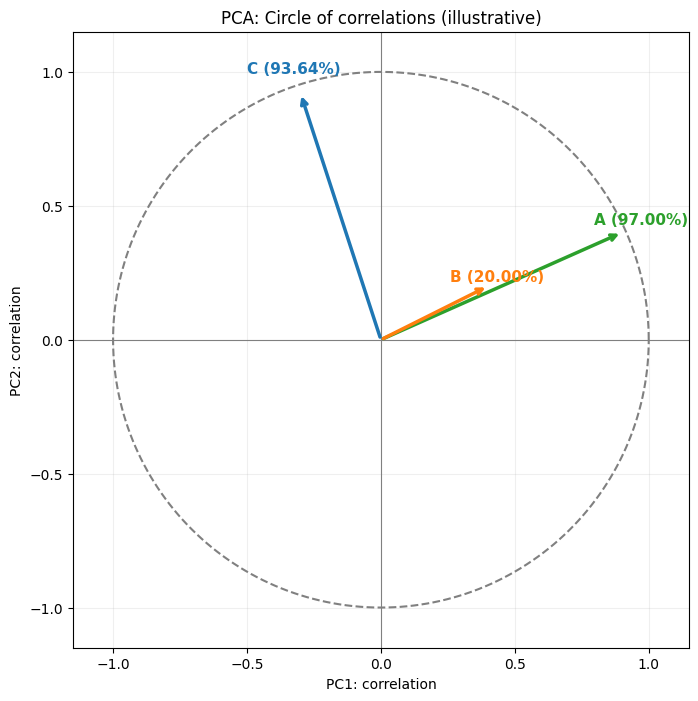

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Illustrative correlations with PC1 and PC2
correlations = pd.DataFrame({
    "Variable": ["A", "B", "C"],
    "PC1": [0.90, 0.40, -0.30],
    "PC2": [0.40, 0.20, 0.92]
})

# Calculate the squared correlations
correlations["PC1²"] = correlations["PC1"] ** 2
correlations["PC2²"] = correlations["PC2"] ** 2

# Squared radius = proportion of variance represented
correlations["r²"] = (
    correlations["PC1²"] + correlations["PC2²"]
)

# Arrow length
correlations["r"] = np.sqrt(correlations["r²"])

# Percentage of variance represented on the factorial plane
correlations["Explained (%)"] = correlations["r²"] * 100

display(Markdown("### Correlation circle calculations"))
display(correlations.round(4))

# Plot the unit circle
fig, ax = plt.subplots(figsize=(8, 8))

theta = np.linspace(0, 2 * np.pi, 500)
ax.plot(
    np.cos(theta),  # X coordinates
    np.sin(theta),  # Y coordinates
    color="grey",
    linestyle="--",
    label="Unit circle"
)

# Principal component axes
ax.axhline(0, color="grey", linewidth=0.8)
ax.axvline(0, color="grey", linewidth=0.8)

colors = ["tab:green", "tab:orange", "tab:blue"]

for (_, row), color in zip(correlations.iterrows(), colors):
    x, y = row["PC1"], row["PC2"]
    #print(f"({x:.2f}, {y:.2f})")

    ax.annotate(
        "",
        xy=(x, y),
        xytext=(0, 0),
        arrowprops=dict(
            arrowstyle="->",
            color=color,
            lw=2.5
        )
    )

    ax.text(
        x * 1.08,
        y * 1.08,
        f"{row['Variable']} ({row['Explained (%)']:.2f}%)",
        color=color,
        fontsize=11,
        fontweight="bold",
        ha="center"
    )

ax.set(
    xlabel="PC1: correlation",
    ylabel="PC2: correlation",
    title="PCA: Circle of correlations (illustrative)"
)

ax.set_xlim(-1.15, 1.15)
ax.set_ylim(-1.15, 1.15)
ax.set_aspect("equal", adjustable="box") # ensures the circle appears circular rather than elliptical due to different axis scales.
ax.grid(alpha=0.2)
plt.show()


In [2]:
display(Markdown(r"""
### Calculating the arrow lengths in the correlation circle

For each original variable $X_j$, the arrow coordinates are its correlations
with the first two principal components:

$$
x_j = \operatorname{Corr}(X_j, PC1)
$$

$$
y_j = \operatorname{Corr}(X_j, PC2)
$$

Using the Pythagorean theorem, the **squared distance** from the origin is:

$$
r_j^2 = x_j^2 + y_j^2
$$

Therefore, the **arrow length** is:

$$
r_j = \sqrt{x_j^2 + y_j^2}
$$

For standardised variables, $r_j^2$ represents the proportion of variance
of variable $X_j$ explained by PC1 and PC2 together.

An arrow close to the circumference ($r \approx 1$) indicates that
the variable is well represented on the factorial plane.
"""))

# Generate mathematical calculations dynamically from the DataFrame.
for _, row in correlations.iterrows():
    variable = row["Variable"]
    pc1 = row["PC1"]
    pc2 = row["PC2"]
    r_squared = row["r²"]
    radius = row["r"]
    percentage = row["Explained (%)"]

    display(Markdown(rf"""
#### Variable {variable}

**Step 1: Calculate the squared distance**

$$
\begin{{aligned}}
r_{{{variable}}}^2
&= \operatorname{{Corr}}({variable},PC1)^2
 + \operatorname{{Corr}}({variable},PC2)^2 \\[6pt]
&= ({pc1:.2f})^2 + ({pc2:.2f})^2 \\[6pt]
&= {pc1**2:.4f} + {pc2**2:.4f} \\[6pt]
&= {r_squared:.4f}
\end{{aligned}}
$$

**Step 2: Calculate the arrow length**

$$
r_{{{variable}}}
= \sqrt{{{r_squared:.4f}}}
\approx {radius:.4f}
$$

**Step 3: Calculate the proportion of variance represented**

$$
\operatorname{{RepresentedVariance}}({variable})
= r_{{{variable}}}^2 \times 100
= {percentage:.2f}\%
$$

**Conclusion:** PC1 and PC2 together represent **{percentage:.2f}%**
of the variance of variable **{variable}**.
"""))



### Calculating the arrow lengths in the correlation circle

For each original variable $X_j$, the arrow coordinates are its correlations
with the first two principal components:

$$
x_j = \operatorname{Corr}(X_j, PC1)
$$

$$
y_j = \operatorname{Corr}(X_j, PC2)
$$

Using the Pythagorean theorem, the **squared distance** from the origin is:

$$
r_j^2 = x_j^2 + y_j^2
$$

Therefore, the **arrow length** is:

$$
r_j = \sqrt{x_j^2 + y_j^2}
$$

For standardised variables, $r_j^2$ represents the proportion of variance
of variable $X_j$ explained by PC1 and PC2 together.

An arrow close to the circumference ($r \approx 1$) indicates that
the variable is well represented on the factorial plane.



#### Variable A

**Step 1: Calculate the squared distance**

$$
\begin{aligned}
r_{A}^2
&= \operatorname{Corr}(A,PC1)^2
 + \operatorname{Corr}(A,PC2)^2 \\[6pt]
&= (0.90)^2 + (0.40)^2 \\[6pt]
&= 0.8100 + 0.1600 \\[6pt]
&= 0.9700
\end{aligned}
$$

**Step 2: Calculate the arrow length**

$$
r_{A}
= \sqrt{0.9700}
\approx 0.9849
$$

**Step 3: Calculate the proportion of variance represented**

$$
\operatorname{RepresentedVariance}(A)
= r_{A}^2 \times 100
= 97.00\%
$$

**Conclusion:** PC1 and PC2 together represent **97.00%**
of the variance of variable **A**.



#### Variable B

**Step 1: Calculate the squared distance**

$$
\begin{aligned}
r_{B}^2
&= \operatorname{Corr}(B,PC1)^2
 + \operatorname{Corr}(B,PC2)^2 \\[6pt]
&= (0.40)^2 + (0.20)^2 \\[6pt]
&= 0.1600 + 0.0400 \\[6pt]
&= 0.2000
\end{aligned}
$$

**Step 2: Calculate the arrow length**

$$
r_{B}
= \sqrt{0.2000}
\approx 0.4472
$$

**Step 3: Calculate the proportion of variance represented**

$$
\operatorname{RepresentedVariance}(B)
= r_{B}^2 \times 100
= 20.00\%
$$

**Conclusion:** PC1 and PC2 together represent **20.00%**
of the variance of variable **B**.



#### Variable C

**Step 1: Calculate the squared distance**

$$
\begin{aligned}
r_{C}^2
&= \operatorname{Corr}(C,PC1)^2
 + \operatorname{Corr}(C,PC2)^2 \\[6pt]
&= (-0.30)^2 + (0.92)^2 \\[6pt]
&= 0.0900 + 0.8464 \\[6pt]
&= 0.9364
\end{aligned}
$$

**Step 2: Calculate the arrow length**

$$
r_{C}
= \sqrt{0.9364}
\approx 0.9677
$$

**Step 3: Calculate the proportion of variance represented**

$$
\operatorname{RepresentedVariance}(C)
= r_{C}^2 \times 100
= 93.64\%
$$

**Conclusion:** PC1 and PC2 together represent **93.64%**
of the variance of variable **C**.


## Thermal propagation and PCA: Lascaux Cave

### 1. What is thermal lag?

**Thermal lag (or phase delay)** describes the time it takes for temperature changes to propagate through a physical environment.

In Lascaux Cave, seasonal temperature changes outside the cave do not reach every recording location simultaneously.

The deeper we move into the cave, the later the corresponding temperature changes occur.

![Heat propagation inside Lascaux Cave](./images/week_4/heat_propagation.png)

*Illustration of the progressive delay in seasonal heat propagation.*

For example, the approximate periods of maximum temperature are:

| Location | Period of maximum temperature |
|---|---|
| Outside the cave | July–August |
| First entrance | September–October |
| Second entrance | October–December |
| Hall of the Bulls | January–March |

This explains the statement from the textbook:

> "The further we go into the cave, the more we advance in time (from the thermal point of view)."

It does not mean that time moves faster inside the cave. Rather, deeper locations experience the same seasonal temperature cycle **later than locations closer to the entrance**.

The surrounding rock stores and releases heat gradually, introducing a delay and generally reducing the amplitude of temperature variations.

### 2. How does PCA reveal thermal propagation?

PCA was applied to temperature measurements from multiple recording locations inside Lascaux Cave.

Importantly, **PCA does not require information about the physical distance between sensors or the time delays**. It identifies patterns in their temperature measurements.

The analysis reveals two related patterns:

1. **Correlation circle (Figure 4.2):** Sensor arrows are arranged approximately counterclockwise according to their locations, progressing from outside the cave towards deeper areas.
2. **Factorial plane of observations (Figure 4.3):** Monthly temperature profiles also progress approximately counterclockwise as the year advances.

These patterns suggest that the seasonal temperature cycle propagates progressively through the cave.

In other words, the correlation structure of the temperature measurements contains information about the delay experienced at different locations.

### 3. Why are angles important?

Seasonal temperature variation can be approximated by a sinusoidal function:

$$
T(t)=\mu+A\cos\left(\frac{2\pi t}{P}-\phi\right)
$$

Where:

- $\mu$ is the average temperature.
- $A$ is the amplitude of the seasonal temperature variation.
- $P$ is the period of the cycle, approximately 12 months.
- $t$ is time, measured in months.
- $\phi$ is the phase angle, representing the temporal shift.

Two sensors can experience similar seasonal temperature patterns but at different times.

The difference between their phase angles can be converted into a time delay:

$$
\boxed{\Delta t=\frac{\Delta\phi}{2\pi}P}
$$

Here, $\Delta\phi$ is measured in radians.

Alternatively, using degrees:

$$
\boxed{\Delta t=\frac{\Delta\phi}{360^\circ}P}
$$

#### Example: A phase difference of 90°

Suppose two sensors have a phase difference of $90^\circ$, and the temperature cycle repeats every 12 months.

$$
\begin{aligned}
\Delta t
&=\frac{90^\circ}{360^\circ}\times12\\[6pt]
&=\frac14\times12\\[6pt]
&=\boxed{3\text{ months}}
\end{aligned}
$$

**Interpretation:** One sensor experiences the same stage of the seasonal temperature cycle approximately three months later than the other.

This is an illustrative calculation. Exact delays require estimating the phase difference from the temperature measurements.

### 4. How is this related to the correlation circle?

The coordinates of each variable in a PCA correlation circle are:

$$
x_j=\operatorname{Corr}(X_j,PC1)
$$

$$
y_j=\operatorname{Corr}(X_j,PC2)
$$

For approximately sinusoidal temperature signals, these coordinates can reflect differences in their seasonal phases.

Consequently:

- Sensors with similar seasonal timing tend to have arrows pointing in similar directions.
- Sensors whose seasonal cycles are delayed relative to one another can appear at different angles.
- The angular progression of sensors can reveal the propagation of seasonal temperature changes through the cave.

**Important:** The angle between PCA arrows is not automatically equal to the physical phase delay. The relationship depends on how well the first two principal components represent the seasonal signals and on the structure of the data.

### 5. Conclusions

1. **Thermal lag** explains why seasonal temperature changes arrive later at deeper locations inside Lascaux Cave.

2. **Thermal inertia** allows the surrounding rock to store and release heat, delaying and attenuating seasonal variations.

3. **PCA identifies patterns** in temperature measurements without requiring explicit information about sensor distances or propagation delays.

4. **The correlation circle** reveals relationships between temperature sensors, including patterns associated with their seasonal timing.

5. **The factorial plane of observations** reveals the progression of monthly temperature profiles throughout the year.

6. **Phase differences** can be converted into approximate time delays when the temperature variations follow a periodic model.

7. **PCA alone does not calculate exact propagation times.** These require additional analysis or assumptions about the seasonal cycles.

**Key takeaway:** PCA can reveal the temporal propagation of a physical phenomenon through the spatial relationships between measured variables. In Lascaux Cave, the angular arrangement of temperature sensors reflects how seasonal heat changes are progressively delayed as they travel deeper into the cave.

**Reference:** [Principal Component Analysis for Data Science — Lascaux Cave](https://pca4ds.github.io/lascaux.html).


## Modelling Thermal Wave Propagation: Comparing Sinusoidal Equations

### 1. The original equations from the Lascaux Cave article

In Section 4.1.4, *Modelling Propagation of Thermal Wave*, the authors propose a sinusoidal model describing temperature variations inside Lascaux Cave.

For **1981**, the equation is:

$$
\boxed{
T_1(i,j)=\alpha_1\sin\left(2\pi(i+j)\right)+\mu_1
}
$$

For **1982**, the equation is:

$$
\boxed{
T_2(i,j)=\alpha_2\sin\left(2\pi(i+j)\right)+\mu_2
}
$$

Where:

- $T_1(i,j)$ and $T_2(i,j)$ represent the modelled temperatures for each year.
- $\alpha_1$ and $\alpha_2$ represent the amplitudes of seasonal temperature variation.
- $\mu_1$ and $\mu_2$ represent the average annual temperatures.
- $i$ represents time (the day of measurement).
- $j$ represents the distance from the cave entrance in the authors' simplified notation.

The authors allow the **amplitude** and **mean temperature** to differ between years.

**Important mathematical clarification:** The argument of a sine function must be dimensionless. Therefore, $i+j$ must represent normalised time and distance-related phase quantities, rather than raw days and metres added together.

The published equations are a simplified model and do not explicitly specify those conversions.

### 2. Comparison with a general sinusoidal model

A general model of periodic temperature variation is:

$$
\boxed{
T(t)=\mu+A\cos\left(\frac{2\pi t}{P}-\phi\right)
}
$$

Where:

- $\mu$ is the mean temperature.
- $A$ is the amplitude.
- $t$ is elapsed time.
- $P$ is the period of the cycle.
- $\phi$ is the phase shift, measured in radians.

For an annual temperature cycle:

$$
P=12\text{ months}
$$

The angular frequency is:

$$
\omega=\frac{2\pi}{P}
$$

Consequently, the model can also be written as:

$$
T(t)=\mu+A\cos(\omega t-\phi)
$$

Both formulations represent **periodic temperature oscillations around an average value**.

### 3. Why are sine and cosine equivalent?

Sine and cosine describe identical periodic waveforms, differing only by a phase shift of $90^\circ$.

Using the trigonometric identity:

$$
\sin(\theta)=\cos\left(\theta-\frac{\pi}{2}\right)
$$

The article's general equation:

$$
T(i,j)=\alpha\sin\left(2\pi(i+j)\right)+\mu
$$

can be rewritten as:

$$
T(i,j)=
\alpha\cos\left(2\pi(i+j)-\frac{\pi}{2}\right)+\mu
$$

Expanding the argument:

$$
T(i,j)=
\alpha\cos\left(
2\pi i+2\pi j-\frac{\pi}{2}
\right)+\mu
$$

Therefore, the sine-based equation can be expressed using cosine without changing the resulting temperatures.

**Conclusion:** The choice between sine and cosine is a matter of phase convention. Both describe the same physical type of periodic behaviour.

### 4. A more explicit model of thermal propagation

To distinguish time from distance, we can write:

$$
\boxed{
T_y(t,d)=\mu_y+
A_y\sin\left(
\frac{2\pi t}{P}-\phi(d)
\right)
}
$$

Where:

- $y$ identifies the year.
- $t$ represents elapsed time.
- $d$ represents distance from the cave entrance.
- $P$ represents the seasonal period.
- $\phi(d)$ represents the distance-dependent phase delay.
- $A_y$ represents the annual amplitude.
- $\mu_y$ represents the annual mean temperature.

If $\tau(d)$ is the time delay experienced at distance $d$, then:

$$
\phi(d)=\frac{2\pi\tau(d)}{P}
$$

Substituting:

$$
T_y(t,d)=\mu_y+
A_y\sin\left(
\frac{2\pi}{P}(t-\tau(d))
\right)
$$

This equation explicitly shows that the temperature cycle at a deeper location is shifted later in time.

**Note:** This is a physically clearer extension of the article's model, not an exact transcription. It assumes that the annual temperature variation can be approximated by a sinusoidal wave with a time delay.

### 5. Converting a phase shift into a time delay

For a periodic signal:

$$
\boxed{
\Delta t=\frac{\Delta\phi}{2\pi}P
}
$$

If the phase difference is expressed in degrees:

$$
\boxed{
\Delta t=\frac{\Delta\phi}{360^\circ}P
}
$$

#### Example: A 90° phase delay

Suppose a sensor deeper inside the cave experiences a $90^\circ$ phase delay relative to an exterior sensor.

For a 12-month cycle:

$$
\begin{aligned}
\Delta t
&=\frac{90^\circ}{360^\circ}\times12\\[6pt]
&=\frac14\times12\\[6pt]
&=\boxed{3\text{ months}}
\end{aligned}
$$

This means that the deeper sensor experiences the corresponding seasonal temperature peak approximately three months later.

In radians:

$$
\begin{aligned}
\Delta\phi
&=90^\circ\frac{\pi}{180^\circ}\\[6pt]
&=\frac{\pi}{2}
\end{aligned}
$$

And:

$$
\Delta t
=\frac{\pi/2}{2\pi}\times12
=\boxed{3\text{ months}}
$$

### 6. Why does the article use two different equations?

The authors model 1981 and 1982 separately because the temperature cycles differ between years.

There are two important parameters:

#### A. Amplitude ($\alpha$)

The amplitude controls the magnitude of seasonal temperature variation.

$$
T_{\max}=\mu+|\alpha|
$$

$$
T_{\min}=\mu-|\alpha|
$$

The total temperature range is:

$$
T_{\max}-T_{\min}=2|\alpha|
$$

Therefore, a larger amplitude produces a greater difference between maximum and minimum temperatures.

In a PCA representation, changing the amplitude of an otherwise comparable seasonal cycle can affect the size of its trajectory on the factorial plane.

#### B. Annual mean temperature ($\mu$)

The mean controls the vertical offset of the sinusoidal temperature function.

Increasing $\mu$ raises the entire temperature curve without changing its amplitude or phase.

If two years have different annual means:

$$
\mu_1\neq\mu_2
$$

their temperature profiles may occupy different regions of the PCA factorial plane.

The authors describe this effect as a separation between the annual loops.

### 7. Relationship with PCA

PCA can reveal the sinusoidal structure of the temperature data through the first two principal components.

For an idealised seasonal model:

$$
\sin(\omega t-\phi_j)
=
\sin(\omega t)\cos(\phi_j)
-
\cos(\omega t)\sin(\phi_j)
$$

This is particularly important because the temperature signal at every sensor can be represented as a combination of two functions:

$$
\sin(\omega t)
\qquad\text{and}\qquad
\cos(\omega t)
$$

Consequently, after removing constant means, an idealised collection of sinusoidal temperature signals with the same frequency has a data matrix of **rank at most two**.

This explains why PCA can represent much of the seasonal behaviour using only two principal components.

In the actual Lascaux Cave dataset, PC1 and PC2 explain approximately 79.69% of the total variance, rather than 100%, because the measurements contain additional environmental effects and variations not captured by a perfect sinusoidal model.

### 8. Conclusions

1. The equations from the article and the general sinusoidal model describe the same type of periodic temperature behaviour.

2. **Sine and cosine are equivalent up to a phase shift of 90°.**

3. The amplitude $\alpha$ controls the magnitude of seasonal temperature variation.

4. The annual mean $\mu$ controls the average temperature level.

5. A phase shift represents the delay in the seasonal temperature cycle between different recording locations.

6. Phase differences can be converted into approximate time delays using the period of the seasonal cycle.

7. The published equations use simplified notation. A dimensionally consistent physical model must distinguish elapsed time, distance and phase delay.

8. PCA can reveal seasonal sinusoidal patterns because phase-shifted sine waves of the same frequency can be expressed using just two underlying functions.

**Key takeaway:** The sinusoidal model explains why seasonal temperature measurements can form loops in the PCA factorial plane. Differences in amplitude, mean temperature and phase delay influence the size, position and relationships of those loops.

**Reference:** [Principal Component Analysis for Data Science — Section 4.1.4: Modelling Propagation of Thermal Wave](https://pca4ds.github.io/lascaux.html).


## 1. Reconstruct the weekly temperatures and apply PCA

The following code uses exactly the phase-offset groups in Table 4.3. It also displays the generated temperature DataFrame and the PCA explained-variance ratios.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from IPython.display import display, Markdown

# --------------------------------------------------
# 1. Parameters from the article
# --------------------------------------------------

WEEKS_PER_YEAR = 52
N_SENSORS = 30

alpha_1981 = 1.0
alpha_1982 = 1.5

# Only the difference between means is specified.
mu_1981 = 12.0
mu_1982 = 11.3  # mu_1981 - mu_1982 = 0.7

# --------------------------------------------------
# 2. Sensor phase offsets from Table 4.3
# --------------------------------------------------

sensor_ids = np.arange(1, N_SENSORS + 1)

def phase_offset(j):
    if 1 <= j <= 8:
        return 2 * np.pi * (j - 8) / 21
    elif 9 <= j <= 15:
        return np.pi / 3
    elif 16 <= j <= 25:
        return np.pi / 2
    else:
        return np.pi

distances = np.array([
    phase_offset(j) for j in sensor_ids
])

sensor_table = pd.DataFrame({
    "Sensor": sensor_ids,
    "Phase (rad)": distances,
    "Phase (degrees)": np.degrees(distances)
})

display(Markdown("### Table 4.3: Sensor phase offsets"))
display(sensor_table.round(3))

# --------------------------------------------------
# 3. Generate weekly temperature observations
# --------------------------------------------------

weeks = np.arange(1, 2 * WEEKS_PER_YEAR + 1)

years = np.where(weeks <= WEEKS_PER_YEAR, 1981, 1982)

# Local week number within each year (1 to 52)
week_in_year = (weeks - 1) % WEEKS_PER_YEAR + 1

temperatures = np.zeros((len(weeks), N_SENSORS))

for i, (year, week) in enumerate(zip(years, week_in_year)):
    if year == 1981:
        alpha, mu = alpha_1981, mu_1981
    else:
        alpha, mu = alpha_1982, mu_1982

    temperatures[i, :] = (
        mu
        + alpha * np.sin(
            2 * np.pi * week / WEEKS_PER_YEAR
            + distances
        )
    )

sensor_columns = [
    f"Sensor_{j:02d}" for j in sensor_ids
]

temperature_df = pd.DataFrame(
    temperatures,
    columns=sensor_columns
)

temperature_df.insert(0, "Week", week_in_year)
temperature_df.insert(0, "Year", years)

display(Markdown("### Reconstructed temperature dataset"))
display(temperature_df.head())

print("Dataset shape:", temperatures.shape)

# --------------------------------------------------
# 4. Apply standardised PCA
# --------------------------------------------------

scaler = StandardScaler()
X_scaled = scaler.fit_transform(temperatures)

pca = PCA(n_components=3)
scores = pca.fit_transform(X_scaled)

explained = pca.explained_variance_ratio_

pca_results = pd.DataFrame({
    "Year": years,
    "Week": week_in_year,
    "PC1": scores[:, 0],
    "PC2": scores[:, 1],
    "PC3": scores[:, 2]
})

variance_summary = pd.DataFrame({
    "Component": ["PC1", "PC2", "PC3"],
    "Eigenvalue": pca.explained_variance_,
    "Explained variance (%)": explained * 100
})

display(Markdown("### PCA explained variance"))
display(variance_summary.round(3))


### Table 4.3: Sensor phase offsets

,Sensor,Phase (rad),Phase (degrees)
0,1,-2.094,-120.000
1,2,-1.795,-102.857
2,3,-1.496,-85.714
3,4,-1.197,-68.571
4,5,-0.898,-51.429
5,6,-0.598,-34.286
6,7,-0.299,-17.143
7,8,0.000,0.000
8,9,1.047,60.000
9,10,1.047,60.000


### Reconstructed temperature dataset

,Year,Week,Sensor_01,Sensor_02,Sensor_03,Sensor_04,Sensor_05,Sensor_06,Sensor_07,Sensor_08,...,Sensor_21,Sensor_22,Sensor_23,Sensor_24,Sensor_25,Sensor_26,Sensor_27,Sensor_28,Sensor_29,Sensor_30
0,1981,1,11.080021,11.005358,11.019075,11.119950,11.299022,11.540379,11.822575,12.120537,...,12.992709,12.992709,12.992709,12.992709,12.992709,11.879463,11.879463,11.879463,11.879463,11.879463
1,1981,2,11.039482,11.000149,11.049657,11.183608,11.390098,11.650781,11.942493,12.239316,...,12.970942,12.970942,12.970942,12.970942,12.970942,11.760684,11.760684,11.760684,11.760684,11.760684
2,1981,3,11.012950,11.009520,11.094098,11.259170,11.490067,11.766275,12.063250,12.354605,...,12.935016,12.935016,12.935016,12.935016,12.935016,11.645395,11.645395,11.645395,11.645395,11.645395
3,1981,4,11.000811,11.033334,11.151749,11.345535,11.597473,11.885177,12.183084,12.464723,...,12.885456,12.885456,12.885456,12.885456,12.885456,11.535277,11.535277,11.535277,11.535277,11.535277
4,1981,5,11.003243,11.071244,11.221769,11.441443,11.710748,12.005754,12.300248,12.568065,...,12.822984,12.822984,12.822984,12.822984,12.822984,11.431935,11.431935,11.431935,11.431935,11.431935


Dataset shape: (104, 30)


### PCA explained variance

,Component,Eigenvalue,Explained variance (%)
0,PC1,18.671,61.639
1,PC2,8.571,28.296
2,PC3,3.049,10.065


## 2. Plot the two annual loops

This plots every weekly observation on the PC1–PC2 factorial plane, connecting consecutive weeks to reveal the annual trajectories.

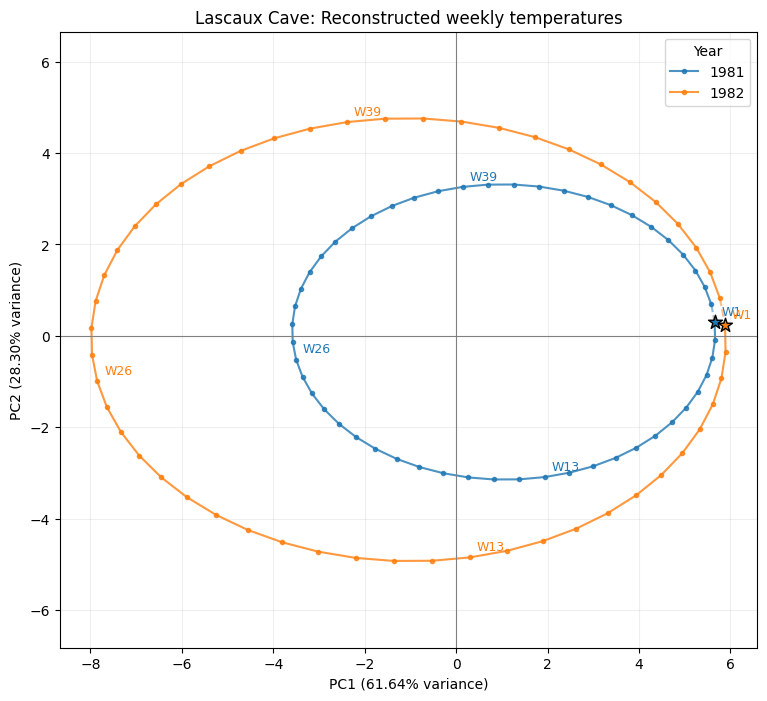

In [4]:
fig, ax = plt.subplots(figsize=(9, 8))

for year, color in [(1981, "tab:blue"), (1982, "tab:orange")]:
    subset = pca_results[pca_results["Year"] == year]

    x = subset["PC1"].to_numpy()
    y = subset["PC2"].to_numpy()

    ax.plot(
        x, y,
        marker="o",
        markersize=3,
        linewidth=1.5,
        alpha=0.8,
        color=color,
        label=str(year)
    )

    # Connect the final week back to the first
    ax.plot(
        [x[-1], x[0]],
        [y[-1], y[0]],
        color=color,
        linestyle="--",
        alpha=0.5
    )

    # Label approximately every three months
    for week in [1, 13, 26, 39]:
        row = subset[subset["Week"] == week].iloc[0]

        ax.annotate(
            f"W{week}",
            (row["PC1"], row["PC2"]),
            xytext=(5, 5),
            textcoords="offset points",
            fontsize=9,
            color=color
        )

    # Mark the first observation of each year
    ax.scatter(
        x[0], y[0],
        s=110,
        marker="*",
        color=color,
        edgecolor="black",
        zorder=5
    )

ax.axhline(0, color="grey", linewidth=0.8)
ax.axvline(0, color="grey", linewidth=0.8)

ax.set(
    xlabel=f"PC1 ({explained[0]:.2%} variance)",
    ylabel=f"PC2 ({explained[1]:.2%} variance)",
    title="Lascaux Cave: Reconstructed weekly temperatures"
)

ax.set_aspect("equal", adjustable="datalim")
ax.legend(title="Year")
ax.grid(alpha=0.2)

plt.show()


## 3. Plot the underlying temperature wave

This second plot shows the temperatures of selected sensors, making the phase delays easier to understand.

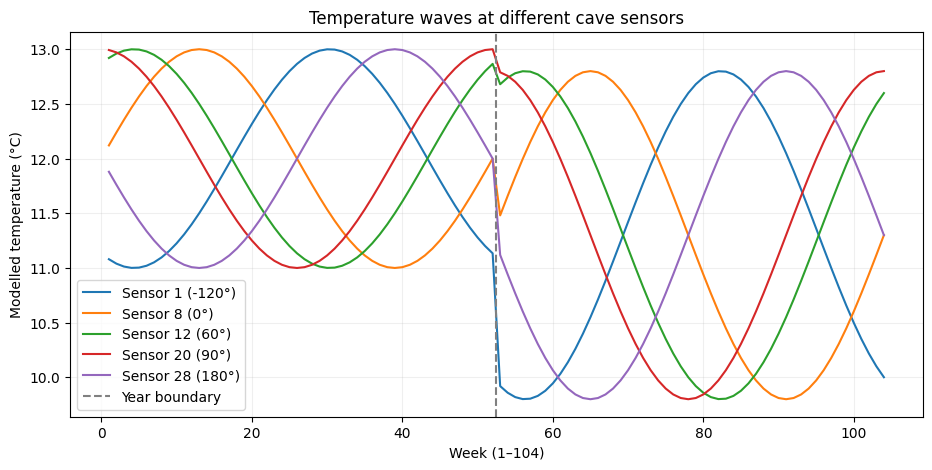

In [5]:
fig, ax = plt.subplots(figsize=(11, 5))

# Compare sensors at different locations/phase offsets
for j in [1, 8, 12, 20, 28]:
    ax.plot(
        weeks,
        temperatures[:, j - 1],
        label=f"Sensor {j} ({np.degrees(distances[j-1]):.0f}°)"
    )

ax.axvline(
    52.5,
    color="grey",
    linestyle="--",
    label="Year boundary"
)

ax.set(
    xlabel="Week (1–104)",
    ylabel="Modelled temperature (°C)",
    title="Temperature waves at different cave sensors"
)

ax.legend()
ax.grid(alpha=0.2)
plt.show()


In [6]:
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from IPython.display import display, Markdown

# --------------------------------------------------
# 1. Original data
# --------------------------------------------------

# From your previous Lascaux Cave simulation
X = temperatures.copy()

N_COMPONENTS = 5
NOISE_LEVEL = 0.25
RANDOM_SEED = 42

rng = np.random.default_rng(RANDOM_SEED)

# --------------------------------------------------
# 2. Add Gaussian noise
# --------------------------------------------------

# Calculate standard deviation for each sensor
sensor_std = X.std(axis=0, ddof=1)

# Generate independent Gaussian noise for each sensor
noise = rng.normal(
    loc=0,
    scale=NOISE_LEVEL * sensor_std,
    size=X.shape
)

X_noisy = X + noise

# --------------------------------------------------
# 3. PCA on original data
# --------------------------------------------------

original_scaler = StandardScaler()
X_original_scaled = original_scaler.fit_transform(X)

original_pca = PCA(n_components=N_COMPONENTS)
original_scores = original_pca.fit_transform(X_original_scaled)

# --------------------------------------------------
# 4. PCA on noisy data
# --------------------------------------------------

noisy_scaler = StandardScaler()
X_noisy_scaled = noisy_scaler.fit_transform(X_noisy)

noisy_pca = PCA(n_components=N_COMPONENTS)
noisy_scores = noisy_pca.fit_transform(X_noisy_scaled)

# --------------------------------------------------
# 5. Correlation between original and noisy PCA scores
# --------------------------------------------------

cross_correlations = np.corrcoef(
    original_scores.T,
    noisy_scores.T
)[:N_COMPONENTS, N_COMPONENTS:]

correlation_df = pd.DataFrame(
    cross_correlations,
    index=[
        f"Original PC{i}"
        for i in range(1, N_COMPONENTS + 1)
    ],
    columns=[
        f"Noisy PC{i}"
        for i in range(1, N_COMPONENTS + 1)
    ]
)

display(Markdown("### Cross-correlation matrix"))
display(correlation_df.round(3))

# --------------------------------------------------
# 6. Diagonal correlations: component stability
# --------------------------------------------------

stability_df = pd.DataFrame({
    "Component": [
        f"PC{i}" for i in range(1, N_COMPONENTS + 1)
    ],
    "Original variance (%)":
        original_pca.explained_variance_ratio_ * 100,
    "Noisy variance (%)":
        noisy_pca.explained_variance_ratio_ * 100,
    "Correlation":
        np.diag(cross_correlations),
    "Absolute correlation":
        np.abs(np.diag(cross_correlations))
})

display(Markdown("### PCA stability summary"))
display(stability_df.round(3))


### Cross-correlation matrix

,Noisy PC1,Noisy PC2,Noisy PC3,Noisy PC4,Noisy PC5
Original PC1,0.998,-0.006,0.004,0.014,0.000
Original PC2,0.006,0.996,-0.006,-0.016,-0.013
Original PC3,-0.003,0.008,0.989,-0.018,-0.007
Original PC4,-0.002,-0.011,-0.001,0.070,-0.073
Original PC5,0.006,0.002,0.005,0.008,-0.072


### PCA stability summary

,Component,Original variance (%),Noisy variance (%),Correlation,Absolute correlation
0,PC1,61.639,58.197,0.998,0.998
1,PC2,28.296,26.731,0.996,0.996
2,PC3,10.065,9.829,0.989,0.989
3,PC4,0.000,0.415,0.070,0.070
4,PC5,0.000,0.382,-0.072,0.072
